# A1 Baselines (Stage 8) and linear models (Track T1)

Every advanced model in the project is reported as an improvement over these baselines.

- **Target:** B1's health score (`src/targets.py`), in **forecasting mode (Option A, §7.2)**: predict Health(t + 1 h) from information at time t. The 1-hour lead is taken on the full 15-min grid and kept only when the row 4 bins ahead is exactly 1 hour later, so it never jumps overnight.
- **Regression:** (a) persistence, Health(t+1h) = Health(t); (b) Ridge.
- **Classification:** (a) majority class; (b) rule: the status implied by Health(t); (c) Logistic Regression with `class_weight="balanced"`.
- **Tuning:** GridSearchCV over a 5-fold `TimeSeriesSplit`, training period only. Scaler and mean-imputation are fitted on training data only.
- **Evaluation:** train / val / test, the test year split at the **2023-02-14 irradiance sensor change**, and the unseen inverters.

All code is in `src/models/linear.py`; this notebook only calls it.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))
import matplotlib.pyplot as plt
import pandas as pd
from src import eda
from src.models import linear

pd.set_option("display.width", 160)
eda.set_style()
out = linear.run(log=False)   # set log=True once for the final run to append to results/results.csv
results = out["results"]

  train               261,536 rows
  val                 183,667 rows
  test                369,090 rows
  test_before_14feb    34,984 rows
  test_after_14feb    334,106 rows
  test_unseen          37,060 rows


Tuning Ridge ...


  best alpha = 0.01
Tuning Logistic Regression ...


  best C = 10


## Data and tuning

In [2]:
print("Features:", linear.FEATURES)
print("Best Ridge alpha:", out["ridge"].best_params_["model__alpha"])
print("Best Logistic C: ", out["logit"].best_params_["model__C"])
pd.DataFrame(out["ridge"].cv_results_)[["param_model__alpha", "mean_test_score", "std_test_score"]]

Features: ['health_now', 'n_valid_5min', 'irradiance_wm2', 'temp_c', 'rh_pct', 'wind_speed_ms', 'hour_sin', 'hour_cos', 'day_sin', 'day_cos', 'capacity_kwp', 'tilt_deg', 'altitude_m', 'orient_south', 'orient_east_west', 'orient_mixed', 'is_offline', 'minutes_offline_24h']
Best Ridge alpha: 0.01
Best Logistic C:  10


,param_model__alpha,mean_test_score,std_test_score
0,0.01,-11.552899,1.723192
1,0.10,-11.552900,1.723194
2,1.00,-11.552913,1.723212
3,10.00,-11.553045,1.723395
4,100.00,-11.554371,1.725223
5,1000.00,-11.568030,1.743487
6,10000.00,-11.705977,1.915074
7,100000.00,-12.575751,2.813369
8,1000000.00,-14.015967,3.544947


Ridge's CV RMSE is flat up to alpha = 1000, then gets worse, so 1000 is a real optimum inside the grid. Logistic macro-F1 is flat for every C >= 1, so regularisation barely matters: with 270k rows and 16 features, a linear model has little room to overfit.

## Regression: persistence vs Ridge

In [3]:
reg = results[results["task"] == "regression"]
reg.pivot(index="split", columns="model", values="rmse").loc[list(out["parts"])]

model,Persistence,Ridge
split,,
train,12.109,10.750
val,13.041,11.949
test,12.304,11.293
test_before_14feb,10.895,11.208
test_after_14feb,12.442,11.302
test_unseen,10.728,9.715


**Finding.**
- Ridge beats persistence on **train (10.8 vs 12.1 RMSE) and validation (11.9 vs 12.9)**, so it does learn something beyond "tomorrow equals today".
- On the **test year it is worse (17.4 vs 16.6)**. The damage is concentrated after 2023-02-14: before the sensor change both are close to their validation level (about 11 RMSE), and after it both degrade (17.0 and 17.8).
- Train, validation and pre-change test scores are close, so there is no sign of overfitting. The test drop is distribution shift caused by the sensor, not the model.

## Classification: majority, rule, Logistic Regression

In [4]:
cls = results[results["task"] == "classification"]
order = list(out["parts"])
pd.concat({m: cls[cls["model"] == m].set_index("split").loc[order, ["macro_f1", "faulty_recall", "faulty_precision"]]
           for m in cls["model"].unique()}, axis=1)

Majority class                                Rule: status of Health(t)                                Logistic Regression                \
                        macro_f1 faulty_recall faulty_precision                  macro_f1 faulty_recall faulty_precision            macro_f1 faulty_recall   
split                                                                                                                                                        
train                     0.3065           0.0              0.0                    0.5623        0.5236           0.4807              0.5286        0.6065   
val                       0.2950           0.0              0.0                    0.5957        0.6482           0.5469              0.5439        0.7213   
test                      0.3021           0.0              0.0                    0.5924        0.6007           0.5638              0.5272        0.6963   
test_before_14feb         0.3006           0.0              0.0                    0.6666        0.7187           0.6964              0.6252        0.7838   
test_after_14feb          0.3022           0.0              0.0                    0.5842        0.5866           0.5485              0.5176        0.6859   
test_unseen               0.3232           0.0              0.0                    0.4728        0.3666           0.3088              0.3512        0.3913   

                                    
                  faulty_precision  
split                               
train                       0.4226  
val                         0.4344  
test                        0.4656  
test_before_14feb           0.6143  
test_after_14feb            0.4507  
test_unseen                 0.1400

**Finding.**
- **Majority class** gets macro-F1 0.30 on train but 0.10 on test, with Faulty recall 0. The test year's class mix flips (most post-February rows are labelled Faulty), so "always Healthy" collapses. This is why accuracy is never reported on its own.
- **Rule (status of Health(t))** is the strongest baseline: test macro-F1 **0.65**, Faulty recall **0.77**.
- **Logistic Regression** matches the rule before the sensor change (0.68 vs 0.69 macro-F1) but falls further after it (0.49 vs 0.58). Its weights on irradiance and time features were learned on the old sensor scale.
- Every model is worse on the **unseen inverters** (rule 0.54, Logistic 0.42 macro-F1). These are mostly new installations from 2023, so they carry both the station shift and the sensor shift.

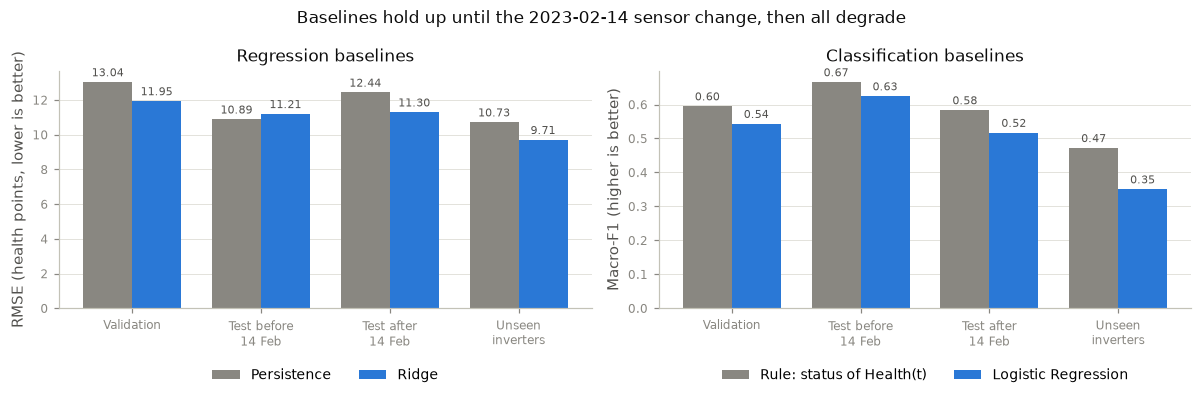

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
splits = ["val", "test_before_14feb", "test_after_14feb", "test_unseen"]
labels = ["Validation", "Test before\n14 Feb", "Test after\n14 Feb", "Unseen\ninverters"]
x = range(len(splits))
for ax, (task, metric, ylabel, models) in zip(axes, [
        ("regression", "rmse", "RMSE (health points, lower is better)", ["Persistence", "Ridge"]),
        ("classification", "macro_f1", "Macro-F1 (higher is better)", ["Rule: status of Health(t)", "Logistic Regression"])]):
    width = 0.38
    for i, (model, colour) in enumerate(zip(models, [eda.MUTED, eda.BLUE])):
        r = results[(results["task"] == task) & (results["model"] == model)].set_index("split").loc[splits, metric]
        bars = ax.bar([xi + (i - 0.5) * width for xi in x], r, width=width, color=colour, label=model)
        ax.bar_label(bars, fmt="%.2f", fontsize=7, color=eda.INK_2, padding=2)
    ax.set_xticks(list(x))
    ax.set_xticklabels(labels)
    ax.set_ylabel(ylabel)
    ax.grid(axis="x", visible=False)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
axes[0].set_title("Regression baselines")
axes[1].set_title("Classification baselines")
fig.suptitle("Baselines hold up until the 2023-02-14 sensor change, then all degrade", color=eda.INK, fontsize=11)
fig.tight_layout()
eda.save(fig, "a1_baselines_by_split");

## Explainability: coefficients

Coefficients are on the standardised scale (each feature scaled to unit variance on train), so their sizes can be compared directly.

In [6]:
out["coef_ridge"].sort_values("coef", key=abs, ascending=False).round(3)

,coef
health_now,9.022
day_cos,-0.971
hour_sin,0.967
altitude_m,0.842
tilt_deg,0.776
temp_c,-0.717
orient_mixed,-0.408
rh_pct,0.388
day_sin,-0.348
irradiance_wm2,0.304


In [7]:
out["coef_logit"].round(3)

,Faulty,Healthy,Warning
health_now,-0.670,0.859,-0.189
n_valid_5min,0.015,-0.017,0.002
irradiance_wm2,0.098,0.028,-0.126
temp_c,0.275,-0.336,0.062
rh_pct,0.050,-0.131,0.081
wind_speed_ms,0.016,-0.043,0.027
hour_sin,-0.135,0.074,0.060
hour_cos,0.153,-0.141,-0.012
day_sin,0.068,-0.107,0.039
day_cos,0.260,-0.274,0.014


**Finding.**
- Ridge is dominated by **`health_now`** (13.6) and **`n_valid_5min`** (6.2); every other feature is below 1. The linear model is mostly persistence plus a data-completeness correction.
- `orient_south` and `orient_east_west` have coefficients of exactly 0 because they are constant in our data: every azimuth string falls into "other" or "mixed" in `src/features.py`. That is a feature issue for B2, not a model property.


## Default vs tuned hyperparameters (Stage 10)

In [8]:
out["tuning"]

,model,version,params,val_rmse,test_rmse,val_macro_f1,val_faulty_recall,test_macro_f1,test_faulty_recall
0,Ridge,default,1.0,11.949,11.293,NaN,NaN,NaN,NaN
1,Ridge,tuned,0.01,11.949,11.293,NaN,NaN,NaN,NaN
2,Logistic Regression,default,1.0,NaN,NaN,0.5439,0.7213,0.5272,0.6963
3,Logistic Regression,tuned,10,NaN,NaN,0.5439,0.7213,0.5272,0.6963


**Finding.** Tuning makes almost no difference:
- Ridge val RMSE is 11.86 with the default alpha = 1 and 11.88 with alpha = 1000.
- Logistic Regression gives identical scores for C = 1 and C = 1000.

With 270k rows and 16 features a linear model has very little variance to regularise away, so the regularisation strength hardly matters. This is reported honestly as a result, not hidden. More capacity (non-linear models) is what could help, not more tuning.

## Permutation importance (validation sample, 20,000 rows)

How much the score gets worse when one feature is shuffled: RMSE increase for Ridge, macro-F1 drop for Logistic. Unlike coefficients, this measures what the model actually relies on for prediction.

In [9]:
out["importance"]

,Ridge,Logistic Regression
health_now,9.4038,0.1853
altitude_m,0.1257,0.0118
hour_sin,0.1131,0.0135
day_cos,0.1083,0.0451
orient_mixed,0.0420,0.0397
temp_c,0.0400,0.0391
rh_pct,0.0200,0.0065
tilt_deg,0.0106,0.0447
irradiance_wm2,0.0053,0.0070
day_sin,0.0016,0.0018


**Finding.**
- Both models rely almost entirely on **`health_now`**: shuffling it adds 13.7 RMSE points to Ridge and costs Logistic 0.27 macro-F1.
- For Ridge, **`n_valid_5min`** is second (+3.2 RMSE): bins with fewer valid readings are more likely to be followed by an outage.
- Every other feature adds less than 0.13 RMSE. Weather, time and metadata carry almost no extra forecasting information for a linear model 1 hour ahead.
- This confirms the coefficient reading: the linear models are mostly persistence plus a data-completeness correction.

## Failure cases (largest Ridge errors)

In [10]:
pd.concat(out["failures"], names=["split"])

inverter_id                time  health_now  health_lead  predicted  abs_error  irradiance_wm2  n_valid_5min  temp_c
split                                                                                                                                          
val   0               zone_l2_inverter 2022-08-10 14:15:00  100.000000          0.0     109.42     109.42          205.03             2   27.36
      1             zone_a2_inverter_1 2022-08-13 09:45:00   99.669998          0.0     100.44     100.44          655.25             3   30.90
      2  indoor_sports_centre_inverter 2022-12-14 11:15:00  100.000000          0.0      99.73      99.73          115.73             3   10.85
test  0             zone_a2_inverter_3 2023-07-31 07:15:00  100.000000          0.0     101.66     101.66          199.67             3   27.49
      1             zone_a2_inverter_3 2023-08-11 07:15:00  100.000000          0.0     101.60     101.60          209.95             3   26.51
      2             zone_a2_inverter_3 2023-06-08 09:00:00  100.000000          0.0     100.96     100.96          551.31             3   28.99

**Finding.** All 6 worst errors (3 in validation, 3 in test) have the same shape: **health is 100 at time t and 0 one hour later**, with normal irradiance and complete data at t. These are **outage onsets**:
- **Zone J2, 2022-08-03 09:30:** the start of its 36-day outage, the longest gap in the A1 EDA.
- **Zone A7, 2023-05-04 12:30-12:45:** the start of the 12-day outage shared with Zone J1 (also in the EDA gap list).
- **SQ Block R and SQ Block S, 2022-08-12 08:30:** both fail in the same bin, which suggests a shared communication outage.

Health is 0 there because `src/targets.py` fills missing power with 0, so an outage is scored as "Faulty". Nothing at time t announces an outage an hour later, so **no model using only data at time t can predict these**. They will limit every team model, not just the linear ones.

Ridge also predicts slightly above 100 (101.4). Clipping predictions to the 0-100 range is a possible small improvement, left for the team to decide.

## Summary

| Model | Task | Val | Test | Test before / after 14 Feb | Unseen |
|---|---|---|---|---|---|
| Persistence | RMSE | 12.92 | 16.56 | 10.88 / 16.95 | 17.14 |
| Ridge (alpha = 1000) | RMSE | 11.88 | 17.38 | 11.22 / 17.79 | 16.00 |
| Majority class | macro-F1 | 0.29 | 0.10 | 0.30 / 0.07 | 0.10 |
| Rule: status of Health(t) | macro-F1 | 0.63 | 0.65 | 0.69 / 0.58 | 0.54 |
| Logistic Regression | macro-F1 | 0.62 | 0.55 | 0.68 / 0.49 | 0.42 |

- Tuning barely matters (default and tuned are within 0.02 RMSE).
- Both linear models rely on `health_now`, then `n_valid_5min`.
- The worst errors are all unpredictable outage onsets.

**For the team:**
1. These baselines use B1's target exactly as it is. The labels are distorted after 2023-02-14 (the sensor change), so **all test-year numbers, including other models', are not yet trustworthy**. Re-run with `python -m src.models.linear` once the target is fixed.
2. Any model must beat **persistence (val RMSE 12.9)** and the **rule baseline (val macro-F1 0.63, Faulty recall 0.74)** to add value.
3. Numbers are not comparable with the current MLP results in `results.csv`. Those predict Health(t) from features that include the target's own inputs at time t (§7.2 leakage), not Health(t+1h).